Installing Necessary Libraries

In [ ]:
!pip install transformers datasets accelerate scikit-learn matplotlib seaborn tqdm
!pip install --upgrade transformers accelerate


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 11.7/11.7 MB 67.3 MB/s eta 0:00:00
  Attempting uninstall: transformers
    Found existing installation: transformers 5.13.1
    Uninstalling transformers-5.13.1:
      Successfully uninstalled transformers-5.13.1


Importing Libraries

In [ ]:
import torch
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from datasets import load_dataset
from transformers import (
    AutoTokenizer,
    AutoModelForSequenceClassification,
    Trainer,
    TrainingArguments,
    DataCollatorWithPadding
)
from sklearn.metrics import accuracy_score, precision_recall_fscore_support, classification_report
from tqdm.auto import tqdm

SEED = 42

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

print("Seed:", SEED)
print("GPU available:", torch.cuda.is_available())


Seed: 42
GPU available: True


Loading Dataset


In [ ]:
print("\nLoading ECHR-A dataset...")

dataset = load_dataset(
    "coastalcph/lex_glue",
    "ecthr_a"
)

print("\nFull dataset:")
print(dataset)


# ============================================================
# 4. CREATE THE EXACT 2,500 / 250 EXPERIMENTAL SUBSET
# ============================================================

dataset_small = DatasetDict({
    "train": dataset["train"]
        .shuffle(seed=SEED)
        .select(range(2500)),

    "test": dataset["test"]
        .shuffle(seed=SEED)
        .select(range(250))
})

print("\nExperimental dataset:")
print(dataset_small)

print("\nTraining examples:", len(dataset_small["train"]))
print("Test examples:", len(dataset_small["test"]))


Loading ECHR-A dataset...

Full dataset:
DatasetDict({
    train: Dataset({
        features: ['text', 'labels'],
        num_rows: 9000
    })
    test: Dataset({
        features: ['text', 'labels'],
        num_rows: 1000
    })
    validation: Dataset({
        features: ['text', 'labels'],
        num_rows: 1000
    })
})

Experimental dataset:
DatasetDict({
    train: Dataset({
        features: ['text', 'labels'],
        num_rows: 2500
    })
    test: Dataset({
        features: ['text', 'labels'],
        num_rows: 250
    })
})

Training examples: 2500
Test examples: 250



TEST LABEL DISTRIBUTION
--------------------------------
Test examples: 250
Total individual labels: 2500
Positive labels: 294
Negative labels: 2206
Positive-label percentage: 11.76 %

All-zero baseline element-wise accuracy: 0.8824

Loading: bert-base-uncased


Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertForSequenceClassification LOAD REPORT from: bert-base-uncased
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.predictions.bias                       | UNEXPECTED | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
cls.predictions.transform.dense.bias       | UNEXPECTED | 
cls.predictions.transform.dense.weight     | UNEXPECTED | 
cls.seq_relationship.weight                | UNEXPECTED | 
cls.seq_relationship.bias                  | UNEXPECTED | 
classifier.weight                          | MISSING    | 
classifier.bias                            | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.



Tokenizing: train


Map:   0%|          | 0/2500 [00:00<?, ? examples/s]


Tokenizing: test


... (14 outputs left out)

Training Loss,Validation Loss,Epoch,Element Accuracy,Full Match Accuracy,Precision,Recall,F1
0.263099,0.226230,4,0.908800,0.372000,0.608458,0.325163,0.376227



Evaluation results:
eval_loss: 0.226230
eval_element_accuracy: 0.908800
eval_full_match_accuracy: 0.372000
eval_precision: 0.608458
eval_recall: 0.325163
eval_f1: 0.376227

Generating predictions...


/tmp/ipykernel_658/216141378.py:163: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.detach().clone() or sourceTensor.detach().clone().requires_grad_(True), rather than torch.tensor(sourceTensor).
  batch["labels"] = torch.tensor(



FINAL METRICS
Element-wise accuracy : 0.9088
Full-match accuracy   : 0.3720
Precision             : 0.6085
Recall                : 0.3252
F1                   : 0.3762

PREDICTION CHECK
Total predicted positive labels: 202
Total actual positive labels: 294
Total predictions: 2500
Percentage of predictions that are positive: 8.08 %

Exactly correct test cases: 93 / 250
Full-match accuracy: 0.372

CLASSIFICATION REPORT
              precision    recall  f1-score  support
Article 2      1.000000  0.428571  0.600000     14.0
Article 3      0.640000  0.627451  0.633663     51.0
Article 5      0.783784  0.467742  0.585859     62.0
Article 6      0.577465  0.532468  0.554054     77.0
Article 8      0.666667  0.062500  0.114286     32.0
Article 9      0.000000  0.000000  0.000000      1.0
Article 10     1.000000  0.058824  0.111111     17.0
Article 11     0.750000  0.333333  0.461538      9.0
Article 14     0.000000  0.000000  0.000000      4.0
Protocol 1     0.666667  0.740741  0.701754     

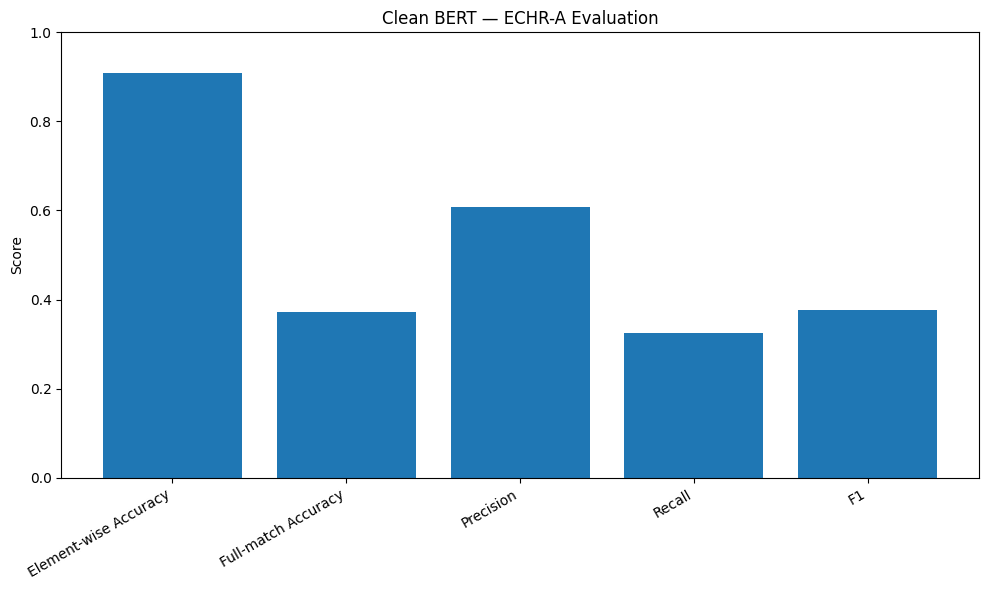

<Figure size 1200x600 with 0 Axes>

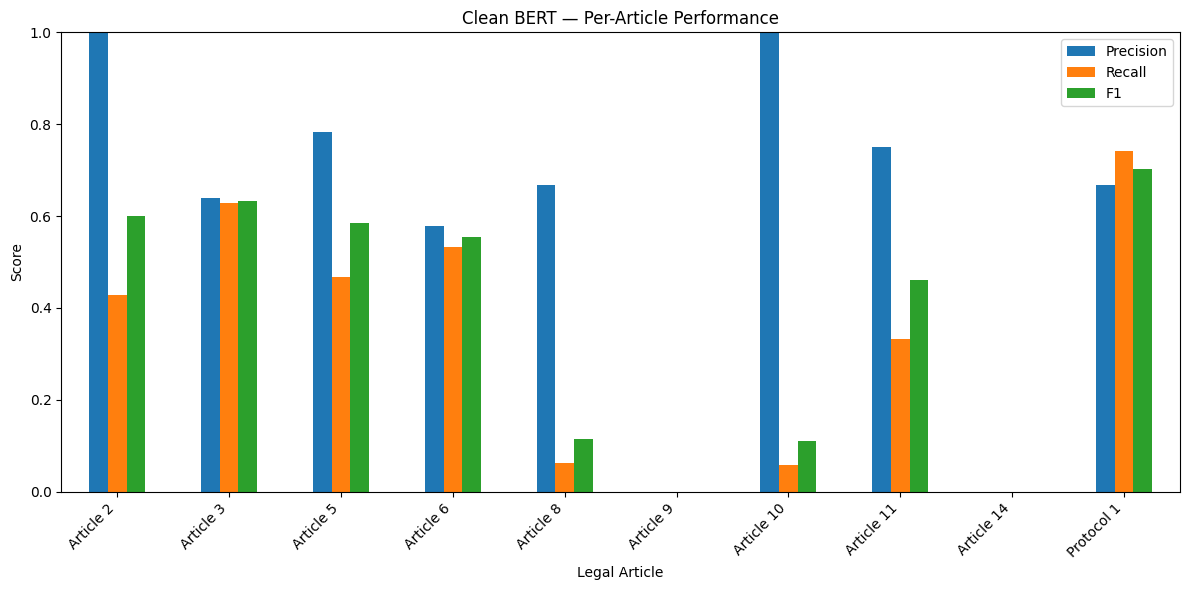



CLEAN BERT EXPERIMENT COMPLETE
Training examples : 2500
Test examples     : 250
Element accuracy  : 0.9088
Full-match accuracy: 0.3720
Precision         : 0.6085
Recall            : 0.3252
F1                : 0.3762
Positive predicted labels: 202

Files saved:
/content/bert_clean_results.csv
/content/bert_clean_classification_report.csv
/content/bert_clean_evaluation.png
/content/bert_clean_per_article.png


In [ ]:
# ============================================================
# 5. CHECK LABEL DISTRIBUTION
# ============================================================

def labels_to_matrix(label_list):
    matrix = []

    for labels in label_list:
        row = [0] * 10

        if isinstance(labels, int):
            if 0 <= labels < 10:
                row[labels] = 1

        elif isinstance(labels, list):
            for label in labels:
                if isinstance(label, int) and 0 <= label < 10:
                    row[label] = 1

        matrix.append(row)

    return np.array(matrix)


test_label_matrix = labels_to_matrix(
    dataset_small["test"]["labels"]
)

print("\nTEST LABEL DISTRIBUTION")
print("--------------------------------")

print("Test examples:", len(test_label_matrix))
print("Total individual labels:", test_label_matrix.size)
print("Positive labels:", int(test_label_matrix.sum()))
print(
    "Negative labels:",
    int(test_label_matrix.size - test_label_matrix.sum())
)
print(
    "Positive-label percentage:",
    round(test_label_matrix.mean() * 100, 2),
    "%"
)

# This shows what accuracy would be obtained by predicting
# ZERO for every article.
all_zero_accuracy = 1 - test_label_matrix.mean()

print(
    "\nAll-zero baseline element-wise accuracy:",
    round(all_zero_accuracy, 4)
)


# ============================================================
# 6. LOAD BERT
# ============================================================

model_name = "bert-base-uncased"

print("\nLoading:", model_name)

tokenizer = AutoTokenizer.from_pretrained(
    model_name
)

model = AutoModelForSequenceClassification.from_pretrained(
    model_name,
    num_labels=10,
    problem_type="multi_label_classification"
)


# ============================================================
# 7. PREPROCESSING
# ============================================================

def preprocess_function(examples):

    # ECHR-A text can be represented as paragraphs.
    if isinstance(examples["text"][0], list):

        texts = [
            " ".join(paragraphs)
            for paragraphs in examples["text"]
        ]

    else:

        texts = examples["text"]


    tokenized_inputs = tokenizer(
        texts,
        truncation=True,
        padding="max_length",
        max_length=512
    )


    # Convert class-index labels into 10-dimensional
    # multi-hot vectors.
    labels = []

    for label in examples["labels"]:

        one_hot = [0] * 10

        if isinstance(label, int):

            if 0 <= label < 10:
                one_hot[label] = 1

        elif isinstance(label, list):

            for l in label:

                if isinstance(l, int) and 0 <= l < 10:
                    one_hot[l] = 1

        labels.append(one_hot)


    tokenized_inputs["labels"] = labels

    return tokenized_inputs


# ============================================================
# 8. TOKENIZE TRAIN + TEST
# ============================================================

tokenized_dataset = {}

for split in ["train", "test"]:

    print("\nTokenizing:", split)

    tokenized_dataset[split] = dataset_small[split].map(
        preprocess_function,
        batched=True,
        batch_size=32,
        num_proc=1,
        remove_columns=dataset_small[split].column_names
    )


print("\nTokenization complete.")


# ============================================================
# 9. DATA COLLATOR
# ============================================================

class MultiLabelDataCollator(DataCollatorWithPadding):

    def __call__(self, features):

        batch = super().__call__(features)

        if "labels" in batch:

            batch["labels"] = torch.tensor(
                batch["labels"],
                dtype=torch.float
            )

        return batch


data_collator = MultiLabelDataCollator(
    tokenizer=tokenizer
)


# ============================================================
# 10. METRICS
# ============================================================

def compute_metrics(eval_pred):

    logits, labels = eval_pred

    # Convert logits to probabilities
    probabilities = 1 / (
        1 + np.exp(-logits)
    )

    # Convert probabilities to binary predictions
    predictions = (
        probabilities >= 0.5
    ).astype(int)


    # --------------------------------------------------------
    # ELEMENT-WISE ACCURACY
    # --------------------------------------------------------

    element_accuracy = accuracy_score(
        labels.flatten(),
        predictions.flatten()
    )


    # --------------------------------------------------------
    # FULL-LABEL-MATCH ACCURACY
    # --------------------------------------------------------

    full_match_accuracy = np.mean(
        np.all(
            labels == predictions,
            axis=1
        )
    )


    # --------------------------------------------------------
    # PRECISION / RECALL / F1
    # --------------------------------------------------------

    precision, recall, f1, _ = (
        precision_recall_fscore_support(
            labels,
            predictions,
            average="macro",
            zero_division=0
        )
    )


    return {

        "element_accuracy":
            element_accuracy,

        "full_match_accuracy":
            full_match_accuracy,

        "precision":
            precision,

        "recall":
            recall,

        "f1":
            f1
    }


# ============================================================
# 11. TRAINING ARGUMENTS
# ============================================================

training_args = TrainingArguments(

    output_dir="/content/bert_clean_output",

    # Batch size
    per_device_train_batch_size=4,
    per_device_eval_batch_size=4,

    # Gradient accumulation
    gradient_accumulation_steps=2,

    # Learning rate
    learning_rate=2e-5,

    # Training duration
    num_train_epochs=4,

    # Weight decay
    weight_decay=0.01,

    # Evaluation
    eval_strategy="epoch",

    # Save checkpoint every epoch
    save_strategy="epoch",

    # Keep best model
    load_best_model_at_end=True,

    metric_for_best_model="eval_f1",

    greater_is_better=True,

    # Logging
    logging_steps=100,

    # Keep only two checkpoints
    save_total_limit=2,

    # Reproducibility
    seed=SEED,

    data_seed=SEED,

    # No external logging
    report_to="none"
)


# ============================================================
# 12. CREATE TRAINER
# ============================================================

trainer = Trainer(

    model=model,

    args=training_args,

    train_dataset=tokenized_dataset["train"],

    eval_dataset=tokenized_dataset["test"],

    data_collator=data_collator,

    compute_metrics=compute_metrics
)


# ============================================================
# 13. TRAIN
# ============================================================

print("\n========================================")
print("STARTING CLEAN BERT TRAINING")
print("========================================")

trainer.train()


# ============================================================
# 14. EVALUATE
# ============================================================

print("\n========================================")
print("FINAL EVALUATION")
print("========================================")

results = trainer.evaluate()


print("\nEvaluation results:")

for key, value in results.items():

    if isinstance(value, (float, np.floating)):

        print(
            f"{key}: {value:.6f}"
        )

    else:

        print(
            f"{key}: {value}"
        )


# ============================================================
# 15. GENERATE PREDICTIONS
# ============================================================

print("\nGenerating predictions...")

test_predictions = trainer.predict(
    tokenized_dataset["test"]
)


logits = test_predictions.predictions

labels = test_predictions.label_ids


# Convert logits → probabilities
probabilities = (
    1 /
    (
        1 +
        np.exp(-logits)
    )
)


# 0.5 threshold
preds = (
    probabilities >= 0.5
).astype(int)


# ============================================================
# 16. CALCULATE METRICS AGAIN DIRECTLY
# ============================================================

element_accuracy = accuracy_score(
    labels.flatten(),
    preds.flatten()
)

full_match_accuracy = np.mean(
    np.all(
        labels == preds,
        axis=1
    )
)

precision, recall, f1, _ = (
    precision_recall_fscore_support(
        labels,
        preds,
        average="macro",
        zero_division=0
    )
)


print("\n========================================")
print("FINAL METRICS")
print("========================================")

print(
    f"Element-wise accuracy : {element_accuracy:.4f}"
)

print(
    f"Full-match accuracy   : {full_match_accuracy:.4f}"
)

print(
    f"Precision             : {precision:.4f}"
)

print(
    f"Recall                : {recall:.4f}"
)

print(
    f"F1                   : {f1:.4f}"
)


# ============================================================
# 17. CHECK WHETHER MODEL PREDICTED ANY POSITIVE LABELS
# ============================================================

print("\n========================================")
print("PREDICTION CHECK")
print("========================================")

print(
    "Total predicted positive labels:",
    int(preds.sum())
)

print(
    "Total actual positive labels:",
    int(labels.sum())
)

print(
    "Total predictions:",
    preds.size
)

print(
    "Percentage of predictions that are positive:",
    round(
        preds.mean() * 100,
        2
    ),
    "%"
)


# ============================================================
# 18. FULL-MATCH COUNT
# ============================================================

correct_full_matches = np.sum(
    np.all(
        labels == preds,
        axis=1
    )
)

total_test_examples = len(labels)

print(
    "\nExactly correct test cases:",
    correct_full_matches,
    "/",
    total_test_examples
)

print(
    "Full-match accuracy:",
    round(
        correct_full_matches /
        total_test_examples,
        4
    )
)


# ============================================================
# 19. CLASSIFICATION REPORT
# ============================================================

article_names = [

    "Article 2",
    "Article 3",
    "Article 5",
    "Article 6",
    "Article 8",
    "Article 9",
    "Article 10",
    "Article 11",
    "Article 14",
    "Protocol 1"

]


report = classification_report(

    labels,

    preds,

    target_names=article_names,

    output_dict=True,

    zero_division=0
)


report_df = pd.DataFrame(
    report
).transpose()


print("\n========================================")
print("CLASSIFICATION REPORT")
print("========================================")

print(
    report_df
)


# ============================================================
# 20. SAVE RESULTS
# ============================================================

results_summary = pd.DataFrame({

    "metric": [

        "element_wise_accuracy",
        "full_match_accuracy",
        "precision",
        "recall",
        "f1"

    ],

    "value": [

        element_accuracy,
        full_match_accuracy,
        precision,
        recall,
        f1

    ]

})


results_summary.to_csv(
    "/content/bert_clean_results.csv",
    index=False
)


report_df.to_csv(
    "/content/bert_clean_classification_report.csv"
)


# ============================================================
# 21. PLOT METRICS
# ============================================================

plt.figure(
    figsize=(10, 6)
)

metric_names = [

    "Element-wise Accuracy",
    "Full-match Accuracy",
    "Precision",
    "Recall",
    "F1"

]

metric_values = [

    element_accuracy,
    full_match_accuracy,
    precision,
    recall,
    f1

]

plt.bar(
    metric_names,
    metric_values
)

plt.ylim(
    0,
    1
)

plt.ylabel(
    "Score"
)

plt.title(
    "Clean BERT — ECHR-A Evaluation"
)

plt.xticks(
    rotation=30,
    ha="right"
)

plt.tight_layout()

plt.savefig(
    "/content/bert_clean_evaluation.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


# ============================================================
# 22. PER-ARTICLE METRICS
# ============================================================

class_metrics = pd.DataFrame({

    "Precision": [
        report[name]["precision"]
        for name in article_names
    ],

    "Recall": [
        report[name]["recall"]
        for name in article_names
    ],

    "F1": [
        report[name]["f1-score"]
        for name in article_names
    ]

}, index=article_names)


plt.figure(
    figsize=(12, 6)
)

class_metrics.plot(
    kind="bar",
    figsize=(12, 6)
)

plt.title(
    "Clean BERT — Per-Article Performance"
)

plt.ylabel(
    "Score"
)

plt.xlabel(
    "Legal Article"
)

plt.xticks(
    rotation=45,
    ha="right"
)

plt.ylim(
    0,
    1
)

plt.tight_layout()

plt.savefig(
    "/content/bert_clean_per_article.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


# ============================================================
# 23. FINAL SUMMARY
# ============================================================

print("\n")
print("=" * 60)
print("CLEAN BERT EXPERIMENT COMPLETE")
print("=" * 60)

print(
    f"Training examples : {len(dataset_small['train'])}"
)

print(
    f"Test examples     : {len(dataset_small['test'])}"
)

print(
    f"Element accuracy  : {element_accuracy:.4f}"
)

print(
    f"Full-match accuracy: {full_match_accuracy:.4f}"
)

print(
    f"Precision         : {precision:.4f}"
)

print(
    f"Recall            : {recall:.4f}"
)

print(
    f"F1                : {f1:.4f}"
)

print(
    f"Positive predicted labels: {int(preds.sum())}"
)

print("\nFiles saved:")

print(
    "/content/bert_clean_results.csv"
)

print(
    "/content/bert_clean_classification_report.csv"
)

print(
    "/content/bert_clean_evaluation.png"
)

print(
    "/content/bert_clean_per_article.png"
)